# 06 - Sensibilidade da roteirização

No notebook 05, três números foram **escolhidos sem teste**: a penalidade de atraso (1 min = 2 km), a capacidade da moto (4 pedidos) e a janela do lote (2 h). E uma simplificação foi feita: o **tempo de espera do lote** não entrava no prazo. Aqui testamos cada um.

**Perguntas**
1. **Penalidade:** quanto de km trocamos por prazo? Existe um ponto de equilíbrio?
2. **Capacidade:** quantos pedidos por viagem compensam?
3. **Janela + espera + volume:** contando que o pedido espera o lote fechar, que janela funciona? E a resposta muda se a demanda for 4 vezes maior?

**Método:** cada cenário roda numa amostra fixa de 200 lotes (seed 42) - mesmos lotes em todos os cenários de penalidade e capacidade, para a comparação ser justa. Código em `src/logistica_rotas/roteirizacao/sensibilidade.py`.

## 1. Configuração

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "src"))

from logistica_rotas.ingestao.leitura import carregar_entregas
from logistica_rotas.limpeza.tratamento import CAMINHO_PROCESSED, limpar_entregas, salvar_parquet

pd.set_option("display.float_format", "{:.1f}".format)
pd.set_option("display.width", 140)

if not CAMINHO_PROCESSED.exists():  # Parquet fica fora do Git: gera a partir do CSV se faltar
    salvar_parquet(limpar_entregas(carregar_entregas()), CAMINHO_PROCESSED)
df = pd.read_parquet(CAMINHO_PROCESSED)

from logistica_rotas.roteirizacao.sensibilidade import carregar_ou_calcular
from logistica_rotas.visualizacao import graficos as g

RECALCULAR = False  # True refaz todos os cenários (cerca de 15 minutos)
sens = carregar_ou_calcular(df, recalcular=RECALCULAR)
colunas = ["metodo", "valor", "entregas", "viagens", "entregas_por_viagem", "economia_km_pct", "no_prazo_pct"]

## 2. Penalidade de atraso: a curva de troca

In [2]:
pen = sens[sens["analise"] == "penalidade"]
pen[colunas].rename(columns={"valor": "penalidade (km/min)"})

,metodo,penalidade (km/min),entregas,viagens,entregas_por_viagem,economia_km_pct,no_prazo_pct
0,individual,0.0,863,863,1.0,0.0,98.7
1,vizinho mais próximo,0.0,863,272,3.2,28.4,75.4
2,OR-Tools,0.0,863,272,3.2,35.0,69.2
3,individual,0.25,863,863,1.0,0.0,98.7
4,OR-Tools com prazo,0.25,863,344,2.5,32.7,90.4
5,individual,0.5,863,863,1.0,0.0,98.7
6,OR-Tools com prazo,0.5,863,354,2.4,32.1,92.2
7,individual,1.0,863,863,1.0,0.0,98.7
8,OR-Tools com prazo,1.0,863,364,2.4,31.1,94.6
9,individual,2.0,863,863,1.0,0.0,98.7


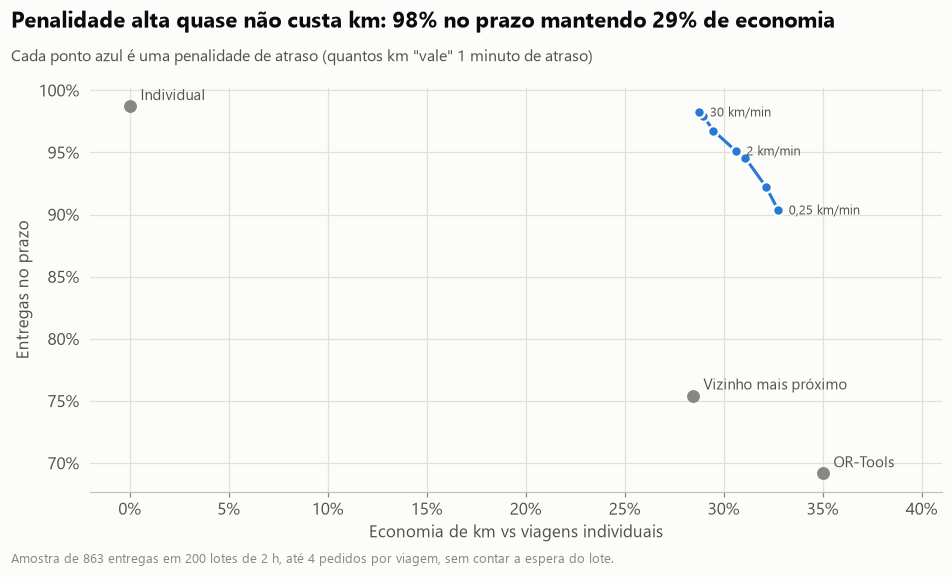

In [3]:
fig = g.curva_troca_penalidade(sens, 'Penalidade alta quase não custa km: 98% no prazo mantendo 29% de economia')
g.salvar_figura(fig, "10_sensibilidade_penalidade");

**Leitura:**
- **Curva achatada:** ao aumentar a penalidade de 0,25 para 30 km/min, as entregas no prazo vão de 90,4% para 98,3%, e a economia de km cai só de 32,7% para 28,8%.
- **Quase de graça:** com penalidade de 30 km/min, o prazo fica praticamente igual ao das viagens individuais (98,7%) e ainda se economizam 28,8% dos km. Isso acontece porque o modelo encontra combinações que respeitam o prazo e custam quase o mesmo que as combinações que o ignoram.
- **O valor escolhido era baixo:** o 2 km/min do notebook 05 dava 95,1%. Um valor entre 10 e 30 km/min é melhor (97,9% a 98,3% no prazo, com 29,0% a 28,8% de economia).
- **Referência:** sem nenhuma consideração de prazo, OR-Tools e vizinho mais próximo economizam mais (35,0% e 28,4%), mas ficam em 69,2% e 75,4% no prazo.

## 3. Capacidade da moto

In [4]:
cap = sens[(sens["analise"] == "capacidade")]
cap[colunas].rename(columns={"valor": "capacidade"})

,metodo,capacidade,entregas,viagens,entregas_por_viagem,economia_km_pct,no_prazo_pct
17,individual,2,863,863,1.0,0.0,98.7
18,OR-Tools com prazo,2,863,503,1.7,24.0,97.8
19,individual,3,863,863,1.0,0.0,98.7
20,OR-Tools com prazo,3,863,391,2.2,29.7,96.2
21,individual,4,863,863,1.0,0.0,98.7
22,OR-Tools com prazo,4,863,369,2.3,30.6,95.1
23,individual,5,863,863,1.0,0.0,98.7
24,OR-Tools com prazo,5,863,365,2.4,30.7,95.1
25,individual,6,863,863,1.0,0.0,98.7
26,OR-Tools com prazo,6,863,365,2.4,30.7,95.1


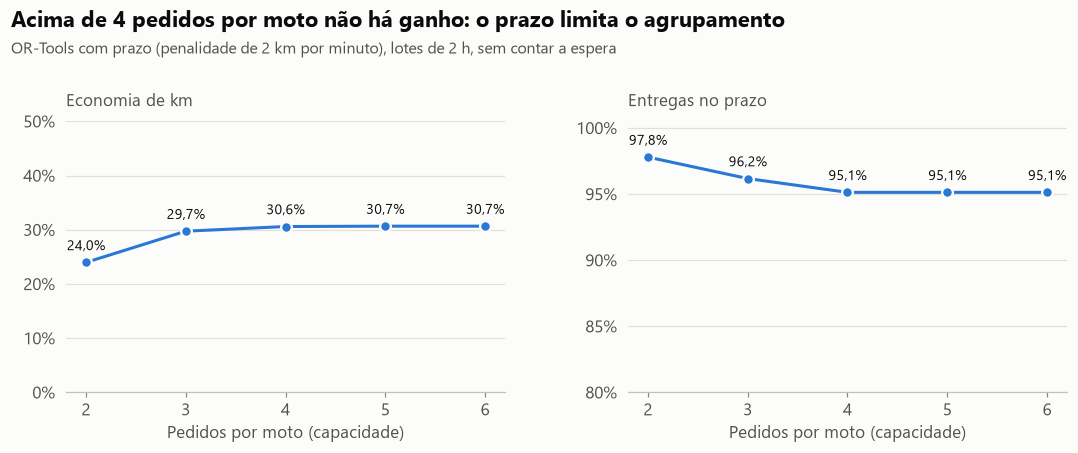

In [5]:
fig = g.sensibilidade_capacidade(sens, 'Acima de 4 pedidos por moto não há ganho: o prazo limita o agrupamento')
g.salvar_figura(fig, "11_sensibilidade_capacidade");

**Leitura:**
- **Com 2 pedidos por moto,** a economia cai para 24,0% (97,8% no prazo).
- **De 3 para 4 pedidos,** a economia sobe pouco (29,7% para 30,6%) e o prazo cai um pouco (96,2% para 95,1%).
- **5 ou 6 pedidos não mudam nada:** o modelo já usa só 2,4 pedidos por viagem em média, porque juntar mais estoura o prazo.
- **Conclusão:** baú para 3 ou 4 pedidos é suficiente. Capacidade extra não é aproveitada com esses prazos.

## 4. Janela do lote, contando a espera, em dois volumes

Agora o prazo de cada pedido em lote é **descontado da espera** até o despacho (fim da janela). O método individual sai na hora, sem espera. Testamos também uma demanda 4 vezes maior (20.000 pedidos no mesmo período), gerada com as mesmas regras.

- **Cobertura:** % das entregas não canceladas que caem em lotes de 2+ pedidos (o resto continua individual).

In [6]:
jan = sens[sens["analise"] == "janela"]
jan[["volume", "valor", "metodo", "entregas", "entregas_por_viagem", "economia_km_pct", "no_prazo_pct",
     "cobertura_pct", "espera_media_min"]].rename(columns={"valor": "janela"})

,volume,janela,metodo,entregas,entregas_por_viagem,economia_km_pct,no_prazo_pct,cobertura_pct,espera_media_min
27,atual (5.000 pedidos),15min,individual,428,1.0,0.0,98.8,30.0,8.1
28,atual (5.000 pedidos),15min,OR-Tools com prazo,428,1.5,12.3,84.1,30.0,8.1
29,atual (5.000 pedidos),30min,individual,454,1.0,0.0,98.5,49.2,15.6
30,atual (5.000 pedidos),30min,OR-Tools com prazo,454,1.3,10.3,50.0,49.2,15.6
31,atual (5.000 pedidos),1h,individual,528,1.0,0.0,98.7,69.9,30.8
32,atual (5.000 pedidos),1h,OR-Tools com prazo,528,1.2,8.7,26.3,69.9,30.8
33,atual (5.000 pedidos),2h,individual,708,1.0,0.0,97.5,86.2,60.6
34,atual (5.000 pedidos),2h,OR-Tools com prazo,708,1.2,12.2,11.3,86.2,60.6
35,4x (20.000 pedidos),15min,individual,525,1.0,0.0,97.7,69.7,7.9
36,4x (20.000 pedidos),15min,OR-Tools com prazo,525,1.6,16.2,84.2,69.7,7.9


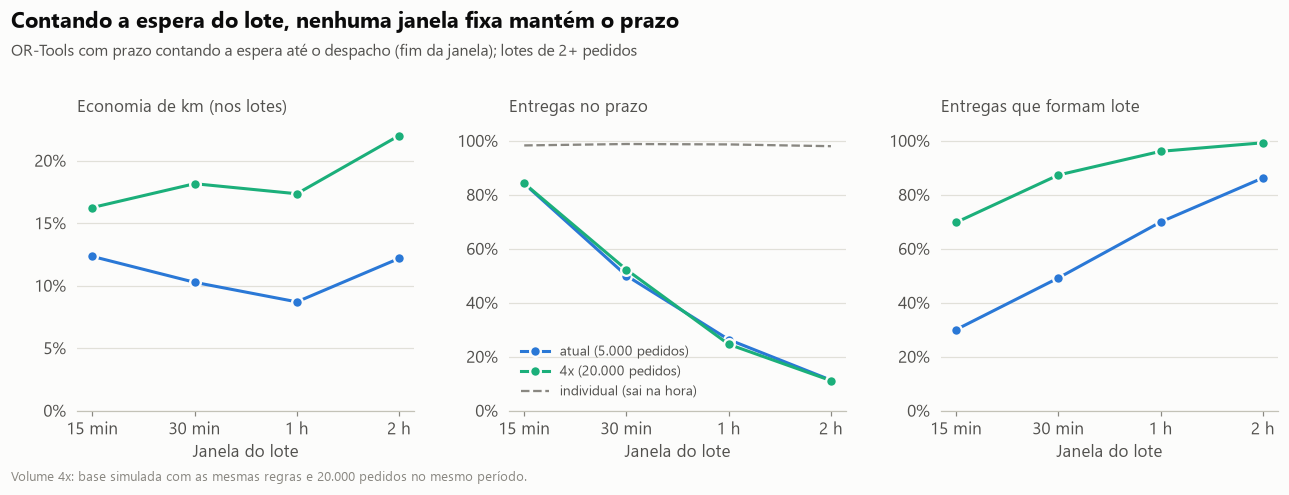

In [7]:
fig = g.sensibilidade_janela(sens, 'Contando a espera do lote, nenhuma janela fixa mantém o prazo')
g.salvar_figura(fig, "12_sensibilidade_janela");

**Leitura - esta seção muda a conclusão do notebook 05:**
- **A espera não cabe no prazo.** Com janela fixa, o pedido espera o lote fechar: 8 min em média na janela de 15 min e 61 min na de 2 h. Os prazos prometidos têm de 15 a 85 min, a maioria entre 20 e 35 min.
- **Mesmo a janela mais curta perde prazo:** com 15 min, só 84,1% das entregas em lote chegam no prazo (contra 98,8% saindo na hora), e a economia é de 12,3%. Com janela de 2 h, só 11,3% chegam no prazo.
- **Volume ajuda a economia, mas não o prazo.** Com 4 vezes mais pedidos, mais entregas formam lote (69,7% contra 30,0% na janela de 15 min), e a economia sobe para 16,2%. As entregas no prazo, porém, ficam iguais (84,2%), porque o problema é a espera.
- **Por que o notebook 05 parecia tão bom:** ele contava o prazo a partir da saída do hub, ou seja, sem espera. Na prática, isso equivale a um despacho que já conhece todos os pedidos da janela, o que não é realista.

## 5. Conclusões

**Conclusões:**
1. **Penalidade:** use 10 a 30 km por minuto de atraso, e não 2. O prazo fica perto do das viagens individuais (97,9% a 98,3%) com praticamente a mesma economia (29,0% a 28,8%), desde que os pedidos já estejam disponíveis.
2. **Capacidade:** 3 a 4 pedidos por viagem bastam. Acima disso o prazo impede de juntar mais.
3. **Janela fixa não funciona com prazos de 20 a 40 minutos.** Contando a espera, até a janela de 15 minutos derruba as entregas no prazo para cerca de 84%, em troca de 12 a 16% de economia. Aumentar o volume não resolve.
4. **O ganho do notebook 05 é um teto teórico.** Os 29% de economia com 96% no prazo só valem se o pedido não precisar esperar outros pedidos.

**Recomendação (hipótese a testar):** trocar a janela fixa por **despacho dinâmico**. A cada novo pedido, a moto sai na hora, ou espera no máximo alguns minutos se houver outro pedido próximo e com prazo folgado. Esse é o próximo experimento natural.

**Limitações:** amostras de 200 lotes por cenário, tempo de viagem determinístico, distância em linha reta multiplicada por 1,3 e hubs hipotéticos.